# TK7 vs 새 TNIK 펩타이드: 구조 기반 다항목 비교

**GPU 불필요. 새 설계를 돌리지 않습니다.** 가진 구조 파일에서 접촉·면적·충돌을 계산합니다.
실제 binding affinity(KD), 결합 자유에너지 또는 억제 효능을 검증하는 도구는 아닙니다.
항목을 합친 임의의 100점 만점 점수는 만들지 않습니다.

## 준비물
- 기존 TNIK 설계 결과 ZIP(v2/v3) 또는 **TNIK과 후보가 함께 들어 있는 복합체 PDB/mmCIF**.
- 펩타이드 단독 구조나 서열만으로 이 비교를 할 수 없습니다.
- 기본값: 후보 복합체 target chain A, peptide chain B. 체인 목록을 보고 필요하면 수정합니다.
- TK7 기준은 9XW0의 author A(TNIK), B(TK7)입니다. label chain 명칭과 다릅니다.

## 실행
CPU 런타임에서 위에서부터 실행 → 파일 업로드 → 체인 확인 → 비교표·그림·ZIP 다운로드.
표면적은 CPU 계산이라 즉시 끝나지는 않을 수 있습니다. 구조마다 진행 표시가 나옵니다.

In [ ]:
#@title 1. CPU 도구 설치
import sys,subprocess
subprocess.check_call([sys.executable,'-m','pip','-q','install','numpy','pandas','matplotlib'])

0

In [ ]:
#@title 2. 비교 함수 불러오기 (내용 수정 불필요)
"""Small static-coordinate reader and Shrake-Rupley SASA. No force-field chemistry."""
from pathlib import Path
import shlex,collections
import numpy as np

class Atom:
    def __init__(self,name,coord,element,occupancy=1,altloc=' '):
        self.name=name;self.coord=np.asarray(coord,float);self.element=element.upper()
        self.occupancy=occupancy;self.altloc=altloc;self.parent=None
    def transform(self,rot,tran):self.coord=self.coord@rot+tran

class Residue:
    def __init__(self,name,number,icode=' '):
        self.resname=name;self.id=(' ',int(number),icode or ' ');self.atoms={}
    def add(self,atom):
        prior=self.atoms.get(atom.name)
        if prior is None or (atom.occupancy,atom.altloc=='A')>(prior.occupancy,prior.altloc=='A'):
            self.atoms[atom.name]=atom;atom.parent=self
    def __iter__(self):return iter(self.atoms.values())
    def __contains__(self,name):return name in self.atoms
    def __getitem__(self,name):return self.atoms[name]
    def __len__(self):return len(self.atoms)

class Chain:
    def __init__(self,name):self.id=name;self.residues=collections.OrderedDict()
    def __iter__(self):return iter(self.residues.values())
    def __len__(self):return len(self.residues)
    def get_atoms(self):return (a for r in self for a in r)

class Model:
    def __init__(self):self.chains=collections.OrderedDict()
    def __iter__(self):return iter(self.chains.values())
    def __getitem__(self,key):return self.chains[key]
    def __contains__(self,key):return key in self.chains
    def get_atoms(self):return (a for c in self for a in c.get_atoms())

class Structure:
    def __init__(self):self.model=Model()
    def __getitem__(self,index):
        if index!=0:raise IndexError('First coordinate model only')
        return self.model
    def get_atoms(self):return self.model.get_atoms()

def read_coordinates(path):
    path=Path(path);st=Structure()
    def add(chain,name,number,icode,atom,xyz,element,occ,alt):
        ch=st.model.chains.setdefault(chain,Chain(chain));key=(number,icode,name)
        r=ch.residues.setdefault(key,Residue(name,number,icode));r.add(Atom(atom,xyz,element,occ,alt))
    if path.suffix.lower() in ('.cif','.mmcif'):
        lines=path.read_text(encoding='utf-8').splitlines();tags=[];tokens=[];inside=False
        for line in lines:
            stripped=line.strip()
            if stripped.startswith('_atom_site.'):
                inside=True;tags.extend(shlex.split(stripped));continue
            if not inside:continue
            if stripped.startswith('#') or stripped=='loop_' or stripped.startswith('_'):
                if tokens:raise ValueError('Incomplete mmCIF atom row')
                if tags:break
                continue
            if not stripped:continue
            if line.startswith(';'):raise ValueError('Multiline atom-site values not supported')
            tokens.extend(shlex.split(line,comments=True))
            while len(tokens)>=len(tags):
                row=dict(zip([t.split('.',1)[1] for t in tags],tokens[:len(tags)]));del tokens[:len(tags)]
                if row.get('pdbx_PDB_model_num','1')!='1':continue
                if row.get('group_PDB') not in ('ATOM','HETATM'):continue
                def pick(auth,label):return row.get(auth) if row.get(auth) not in (None,'.','?') else row.get(label)
                chain=pick('auth_asym_id','label_asym_id');name=pick('auth_comp_id','label_comp_id')
                number=pick('auth_seq_id','label_seq_id')
                if number in (None,'.','?'):raise ValueError('Atom without a residue number')
                icode=row.get('pdbx_PDB_ins_code',' ');icode=' ' if icode in ('.','?') else icode
                alt=row.get('label_alt_id',' ');alt=' ' if alt in ('.','?') else alt
                add(chain,name,int(number),icode,pick('auth_atom_id','label_atom_id'),
                    [float(row['Cartn_'+axis]) for axis in 'xyz'],row['type_symbol'],float(row.get('occupancy',1)),alt)
        if not tags:raise ValueError('No atom_site loop in mmCIF')
    else:
        for line in path.read_text(encoding='utf-8').splitlines():
            if line.startswith('ENDMDL'):break
            if not line.startswith(('ATOM  ','HETATM')):continue
            atom=line[12:16].strip();element=line[76:78].strip() if len(line)>=78 else ''
            if not element:element=next((c for c in atom if c.isalpha()),'')
            add(line[21],line[17:20].strip(),int(line[22:26]),line[26],atom,
                [float(line[a:b]) for a,b in [(30,38),(38,46),(46,54)]],element,
                float(line[54:60].strip() or 1),line[16])
    if not any(True for a in st.get_atoms()):raise ValueError('No atoms parsed')
    if not all(np.isfinite(a.coord).all() for a in st.get_atoms()):raise ValueError('Nonfinite coordinates')
    return st

def sasa_values(atoms,n_points=200):
    """Golden-spiral Shrake-Rupley, Bondi-style element radii, probe 1.4 A."""
    radii={'H':1.2,'C':1.7,'N':1.55,'O':1.52,'S':1.8,'P':1.8,'F':1.47,'CL':1.75,'BR':1.85,'I':1.98}
    if n_points<20:raise ValueError('At least 20 SASA sphere points required')
    unknown={a.element for a in atoms}-radii.keys()
    if unknown:raise ValueError('Unsupported SASA elements: '+','.join(sorted(unknown)))
    xyz=np.array([a.coord for a in atoms]);r=np.array([radii[a.element]+1.4 for a in atoms])
    k=np.arange(n_points);z=1-2*(k+.5)/n_points;phi=k*np.pi*(3-np.sqrt(5))
    circle=np.sqrt(1-z*z);sphere=np.column_stack((circle*np.cos(phi),circle*np.sin(phi),z))
    areas=np.zeros(len(atoms))
    for i,point in enumerate(xyz):
        near=[int(j) for j in np.where(((xyz-point)**2).sum(axis=1)<(r+r[i])**2)[0] if j!=i]
        sample=point+r[i]*sphere
        visible=np.ones(n_points,bool)
        if near:
            near=np.asarray(near)
            # Chunk neighbors to bound memory for large/packed structures.
            for start in range(0,len(near),64):
                ix=near[start:start+64]
                covered=(((sample[:,None,:]-xyz[ix][None,:,:])**2).sum(-1)<r[ix][None,:]**2).any(axis=1)
                visible &= ~covered
        areas[i]=4*np.pi*r[i]**2*visible.mean()
    return areas

def global_pairs(a,b):
    """Global sequence alignment, linear gap -3, match 2, mismatch -2."""
    score=np.zeros((len(a)+1,len(b)+1));trace=np.zeros_like(score,dtype=np.int8)
    score[:,0]=-3*np.arange(len(a)+1);score[0,:]=-3*np.arange(len(b)+1)
    trace[1:,0]=1;trace[0,1:]=2
    for i in range(1,len(a)+1):
        for j in range(1,len(b)+1):
            values=(score[i-1,j-1]+(2 if a[i-1]==b[j-1] else -2),score[i-1,j]-3,score[i,j-1]-3)
            best=int(np.argmax(values));score[i,j]=values[best];trace[i,j]=best
    i,j=len(a),len(b);pairs=[]
    while i or j:
        direction=trace[i,j]
        if i and j and direction==0:pairs.append((i-1,j-1));i-=1;j-=1
        elif i and (direction==1 or not j):i-=1
        else:j-=1
    return pairs[::-1]

"""Static TNIK-interface descriptors. Not a binding-affinity or energy predictor."""
from pathlib import Path
import collections, hashlib, json, math
import numpy as np
import pandas as pd


AA3='ALA ARG ASN ASP CYS GLN GLU GLY HIS ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL'.split()
AA1=dict(zip(AA3,'ARNDCQEGHILKMFPSTWYV'))

CANONICAL={'TPO':'THR','SEP':'SER','PTR':'TYR','MSE':'MET'}
STANDARD=set('ALA ARG ASN ASP CYS GLN GLU GLY HIS ILE LEU LYS MET PHE PRO SER THR TRP TYR VAL'.split())
SC_DONORS={'ARG':{'NE','NH1','NH2'},'LYS':{'NZ'},'ASN':{'ND2'},'GLN':{'NE2'},'SER':{'OG'},'THR':{'OG1'},'TYR':{'OH'},'TRP':{'NE1'}}
SC_ACCEPTORS={'ASP':{'OD1','OD2'},'GLU':{'OE1','OE2'},'ASN':{'OD1'},'GLN':{'OE1'},'SER':{'OG'},'THR':{'OG1'},'TYR':{'OH'},'TPO':{'O1P','O2P','O3P'}}

def read_structure(path):
    return read_coordinates(path)

def inventory(path):
    return [{'chain':c.id,'residues_with_CA':sum('CA' in r for r in c),'residues_total':len(c)} for c in read_structure(path)[0]]

def chosen_atoms(residue):
    return [a for a in residue if a.element not in ('H','D')]

def protein_residues(chain):
    return [r for r in chain if 'CA' in r and CANONICAL.get(r.resname,r.resname) in STANDARD]

def residue_label(r):
    return f'{r.resname}:{r.id[1]}{r.id[2].strip()}'

def canonical_sequence(residues):
    return ''.join(AA1[CANONICAL.get(r.resname,r.resname)] for r in residues)

def complex_parts(path,target_chain,peptide_chain):
    model=read_structure(path)[0]
    if target_chain==peptide_chain or target_chain not in model or peptide_chain not in model:
        raise ValueError('Separate existing target and peptide chains required. Check chain inventory.')
    target=protein_residues(model[target_chain])
    # Include all non-water/non-ion peptide residues and caps on the explicitly selected chain.
    peptide=[r for r in model[peptide_chain] if r.resname not in ('HOH','WAT','NA','CL','K','MG','CA','ZN') and len(chosen_atoms(r))>1]
    if len(target)<100 or not peptide:
        raise ValueError('Target is unexpectedly short or selected peptide chain is empty.')
    return target,peptide

def target_mapping(reference,candidate):
    a,b=canonical_sequence(reference),canonical_sequence(candidate)
    pairs=global_pairs(a,b)
    matches=sum(a[i]==b[j] for i,j in pairs)
    identity=matches/max(1,len(pairs));coverage=len(pairs)/len(a)
    if identity<.95 or coverage<.8:
        raise ValueError(f'TNIK sequence mismatch: identity={identity:.3f}, reference coverage={coverage:.3f}')
    mapping={candidate[j].id:reference[i].id for i,j in pairs}
    x=np.array([reference[i]['CA'].coord for i,j in pairs]);y=np.array([candidate[j]['CA'].coord for i,j in pairs])
    xc,yc=x.mean(0),y.mean(0);u,s,v=np.linalg.svd((y-yc).T@(x-xc));rot=u@v
    if np.linalg.det(rot)<0:u[:,-1]*=-1;rot=u@v
    rmsd=np.sqrt(np.mean(np.sum(((y-yc)@rot-(x-xc))**2,axis=1)))
    return mapping,dict(target_alignment_identity=identity,target_reference_coverage=coverage,target_CA_RMSD_to_reference_A=float(rmsd))

def buried_area(target,peptide,n_points=200):
    ta=[a for r in target for a in chosen_atoms(r)];pa=[a for r in peptide for a in chosen_atoms(r)]
    combined=sasa_values(ta+pa,n_points);at=sasa_values(ta,n_points).sum();ap=sasa_values(pa,n_points).sum()
    dt=float(at-combined[:len(ta)].sum());dp=float(ap-combined[len(ta):].sum())
    return dict(target_buried_SASA_A2=dt,peptide_buried_SASA_A2=dp,
                total_SASA_loss_A2=dt+dp,interface_area_half_total_loss_A2=(dt+dp)/2,
                peptide_buried_SASA_fraction=dp/max(ap,1e-9))

def is_donor(a):
    r=a.parent
    return (a.name=='N' and r.resname!='PRO') or a.name in SC_DONORS.get(r.resname,set())

def is_acceptor(a):
    return a.name in ('O','OXT') or a.name in SC_ACCEPTORS.get(a.parent.resname,set())

def static_metrics(path,target_chain,peptide_chain,reference_target,reference_contact_ids,n_points=200):
    target,peptide=complex_parts(path,target_chain,peptide_chain)
    mapping,alignment=target_mapping(reference_target,target)
    ta=[a for r in target for a in chosen_atoms(r)];pa=[a for r in peptide for a in chosen_atoms(r)]
    d=np.linalg.norm(np.array([a.coord for a in ta])[:,None,:]-np.array([a.coord for a in pa])[None,:,:],axis=-1)
    contacts=[];residue_pairs=set();contact_target_ids=set();binder_ids=set()
    for i,j in zip(*np.where(d<5.0)):
        a,b=ta[i],pa[j];rid=mapping.get(a.parent.id)
        if rid is not None:contact_target_ids.add(rid)
        binder_ids.add(b.parent.id);residue_pairs.add((a.parent.id,b.parent.id))
        contacts.append(dict(target_residue=residue_label(a.parent),peptide_residue=residue_label(b.parent),
            target_atom=a.name,peptide_atom=b.name,distance_A=float(d[i,j]),
            NO_donor_acceptor_distance_proxy=bool(d[i,j]<=3.5 and ((is_donor(a) and is_acceptor(b)) or (is_acceptor(a) and is_donor(b))))))
    # Side-chain charge contact proxy: no protonation/ionic-strength model; no energy claim.
    positive=lambda a:a.name in ({'NZ'} if a.parent.resname=='LYS' else {'NE','NH1','NH2'} if a.parent.resname=='ARG' else set())
    negative=lambda a:a.name in SC_ACCEPTORS.get(a.parent.resname,set()) and a.parent.resname in ('ASP','GLU','TPO')
    salt=set()
    for i,j in zip(*np.where(d<=4.0)):
        a,b=ta[i],pa[j]
        if (positive(a) and negative(b)) or (negative(a) and positive(b)):salt.add((a.parent.id,b.parent.id))
    ref=set(reference_contact_ids);intersection=contact_target_ids&ref;union=contact_target_ids|ref
    full_sequence=canonical_sequence([r for r in peptide if CANONICAL.get(r.resname,r.resname) in STANDARD])
    counts=collections.Counter(full_sequence);probs=[x/max(1,len(full_sequence)) for x in counts.values()]
    metrics=dict(**alignment,target_resolved_residues=len(target),peptide_resolved_groups=len(peptide),
        peptide_heavy_atoms=len(pa),minimum_interchain_distance_A=float(d.min()),
        heavy_atom_contact_pairs_5A=len(contacts),residue_contact_pairs_5A=len(residue_pairs),
        peptide_contacting_residues_5A=len(binder_ids),peptide_contact_fraction_5A=len(binder_ids)/len(peptide),
        reference_site_recall_5A=len(intersection)/len(ref) if ref else None,
        reference_site_Jaccard_5A=len(intersection)/len(union) if union else None,
        interchain_pairs_below_1p8A=int((d<1.8).sum()),
        donor_acceptor_distance_pairs_3p5A=sum(c['NO_donor_acceptor_distance_proxy'] for c in contacts),
        charged_sidechain_residue_pairs_4A=len(salt),resolved_standard_fragment_sequence=full_sequence,
        maximum_single_AA_fraction=max(probs,default=0),sequence_entropy_bits=-sum(p*math.log2(p) for p in probs),
        noncanonical_residue_names=','.join(sorted({r.resname for r in target+peptide if r.resname not in STANDARD})),
        **buried_area(target,peptide,n_points))
    warns=[]
    if metrics['interchain_pairs_below_1p8A']:warns.append('very_close_interchain_atoms_check_bond_chemistry_or_clashes')
    if metrics['peptide_contacting_residues_5A']==0:warns.append('no_5A_contact')
    if metrics['target_CA_RMSD_to_reference_A']>3:warns.append('large_target_conformation_difference')
    warns.append('static_geometry_only_not_KD_or_binding_free_energy')
    return metrics,contacts,sorted(contact_target_ids),warns

def compare(reference_path,candidates,out_dir,ref_target_chain='A',ref_peptide_chain='B',n_points=200):
    """candidates: list of {name,path,target_chain,peptide_chain,source_type}."""
    out_dir=Path(out_dir);out_dir.mkdir(parents=True,exist_ok=True)
    rt,rp=complex_parts(reference_path,ref_target_chain,ref_peptide_chain)
    ta=[a for r in rt for a in chosen_atoms(r)];pa=[a for r in rp for a in chosen_atoms(r)]
    dist=np.linalg.norm(np.array([a.coord for a in ta])[:,None,:]-np.array([a.coord for a in pa])[None,:,:],axis=-1)
    refids={ta[i].parent.id for i in np.where((dist<5).any(axis=1))[0]}
    cases=[dict(name='TK7_reference_resolved_fragment',path=str(reference_path),target_chain=ref_target_chain,
        peptide_chain=ref_peptide_chain,source_type='experimental_9XW0_partial_coordinates')]+candidates
    rows=[];details=[]
    for index,case in enumerate(cases):
        print(f'[{index+1}/{len(cases)}] {case["name"]}: contacts and SASA...',flush=True)
        try:
            metrics,contacts,ids,warns=static_metrics(case['path'],case['target_chain'],case['peptide_chain'],rt,refids,n_points)
            row=dict(name=case['name'],source_type=case.get('source_type','unknown'),**metrics,error='')
            pd.DataFrame(contacts,columns=['target_residue','peptide_residue','target_atom','peptide_atom','distance_A','NO_donor_acceptor_distance_proxy']).to_csv(out_dir/f'contacts_{index:03d}.csv',index=False)
            details.append(dict(name=case['name'],warnings=warns,target_contact_ids=ids,
                source_sha256=hashlib.sha256(Path(case['path']).read_bytes()).hexdigest()))
        except Exception as exc:
            if index==0:raise
            row=dict(name=case['name'],source_type=case.get('source_type','unknown'),error=f'{type(exc).__name__}: {exc}')
            details.append(dict(name=case['name'],warnings=['comparison_failed'],error=row['error']))
        rows.append(row);pd.DataFrame(rows).to_csv(out_dir/'comparison.csv',index=False)
    caveats=[
        'NO affinity/KD/IC50/composite score is produced. Metrics are geometric descriptors.',
        'Reference is resolved TK7 fragment, not complete TiB chemical model. Missing atoms lower or alter descriptors.',
        'Experimental TK7 and predicted candidates are not equally certain structures.',
        'Candidate TNIK may be TPO->THR simplified; reference retains phosphate atoms. Energy comparison is not valid.',
        'SASA is computed in fixed bound conformations; total SASA loss and half-loss area are both explicitly named.',
        'Polar and charge distances are proxies, not validated hydrogen bonds or energies. No angle/protonation modeling.',
        'Counts depend on peptide size; normalized fractions also provided. More contacts/area does not prove tighter affinity.',
        'No MD, force-field parameterization or MM/PBSA is performed. No fake energy or potency is calculated.']
    (out_dir/'audit.json').write_text(json.dumps(dict(details=details,caveats=caveats,
        settings=dict(contact_cutoff_A=5,polar_proxy_cutoff_A=3.5,charge_proxy_cutoff_A=4,
            close_atom_cutoff_A=1.8,SASA_probe_A=1.4,SASA_points=n_points,SASA_P_radius_A=1.8)),ensure_ascii=False,indent=2),encoding='utf-8')
    return pd.DataFrame(rows)

In [ ]:
#@title 3. 후보 복합체 또는 기존 결과 ZIP 업로드
from google.colab import files
import zipfile,io,csv,datetime
from urllib.request import urlretrieve
BASE=Path('/content')
WORK=BASE/('TK7_compare_'+datetime.datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
WORK.mkdir()
INPUT=WORK/'inputs';INPUT.mkdir()
uploaded=files.upload()
if not uploaded:raise ValueError('후보 복합체 파일을 업로드하세요.')
candidate_paths=[];reference_path=None;extra_notes=[]
def safe_member(z,name,destination):
    # Only individually selected regular data files are read, never extractall.
    pure=Path(name.replace('\\','/'))
    if pure.is_absolute() or '..' in pure.parts:raise ValueError('Unsafe ZIP member path')
    info=z.getinfo(name)
    if info.file_size>100_000_000:raise ValueError('Unexpectedly large structure file')
    target=destination/pure.name
    if target.exists():raise ValueError('Duplicate structure basename; upload separately.')
    target.write_bytes(z.read(name));return target
for upload_index,(filename,data) in enumerate(uploaded.items()):
    destination=INPUT/f'upload_{upload_index}';destination.mkdir()
    if filename.lower().endswith('.zip'):
        with zipfile.ZipFile(io.BytesIO(data)) as z:
            names=z.namelist()
            refs=[x for x in names if x.endswith('9XW0_original.cif')]
            if refs and reference_path is None:reference_path=safe_member(z,refs[0],destination)
            tables=[x for x in names if x.endswith('validation_all.csv')]
            if tables:
                if z.getinfo(tables[0]).file_size>10_000_000:raise ValueError('Validation table too large')
                prefix=tables[0][:-len('validation_all.csv')]
                rows=list(csv.DictReader(io.StringIO(z.read(tables[0]).decode('utf-8-sig'))))
                seen=set()
                for row in rows:
                    member=prefix+row.get('structure_file','')
                    if row.get('kind')=='design' and not row.get('error') and row.get('structure_file') and member in names and member not in seen:
                        candidate_paths.append(safe_member(z,member,destination));seen.add(member)
                extra_notes.append('ZIP: selected evaluated design predictions only; shuffled controls excluded.')
            elif any(x.endswith('design.pdb') for x in names):
                member=next(x for x in names if x.endswith('design.pdb'))
                candidate_paths.append(safe_member(z,member,destination))
                extra_notes.append('Only design.pdb available: this is the design pose, not independently validated.')
    elif filename.lower().endswith(('.pdb','.cif','.mmcif')):
        path=destination/Path(filename).name;path.write_bytes(data);candidate_paths.append(path)
    else:extra_notes.append('Ignored unsupported file: '+filename)
if not candidate_paths:raise ValueError('후보 복합체를 찾지 못했습니다. TNIK+후보가 들어 있는 PDB를 업로드하세요.')
if reference_path is None:
    reference_path=INPUT/'9XW0_original.cif'
    urlretrieve('https://files.rcsb.org/download/9XW0.cif',reference_path)
print('TK7 reference:',reference_path)
for path in candidate_paths:
    print('후보:',path.name);display(pd.DataFrame(inventory(path)))
print(*extra_notes,sep='\n')

Saving design.pdb to design.pdb
TK7 reference: /content/TK7_compare_20261103_120544_782559/inputs/9XW0_original.cif
후보: design.pdb


,chain,residues_with_CA,residues_total
0,A,299,299
1,B,16,16


## 4. 체인 설정과 결과 해석 주의
아래 기본 설정은 우리 설계 코드의 결과(A=TNIK, B=후보)에 맞춰져 있습니다.
다른 구조이면 위 체인 목록을 보고 변경하세요. 후보마다 다르면 `CANDIDATES` 목록에서 따로 변경합니다.
TK7 기준 파일은 알려진 9XW0입니다. TK7의 미해결 부분과 특수 연결부 전체를 복원하지 않으므로
**비교 대상은 완전한 TK7 분자가 아니라 좌표가 있는 부분의 인터페이스**입니다.

reference의 인산화 TNIK과 단순화한 후보 TNIK의 화학적 상태도 다릅니다.
그림/표에서 어느 쪽이 높아도 “TK7보다 결합력이 좋다”고 결론 내리지 않습니다.

In [ ]:
#@title 4. 후보 체인 설정
TARGET_CHAIN='A'
PEPTIDE_CHAIN='B'
SASA_POINTS=200  # 모든 구조에 동일 적용. 정확한 에너지 계산이 아닌 표면적 근사.
CANDIDATES=[dict(name=f'candidate_{i+1}_{p.stem}',path=str(p),target_chain=TARGET_CHAIN,
    peptide_chain=PEPTIDE_CHAIN,source_type='user_supplied_or_predicted_complex') for i,p in enumerate(candidate_paths)]
display(pd.DataFrame(CANDIDATES))

,name,path,target_chain,peptide_chain,source_type
0,candidate_1_design,/content/TK7_compare_20261103_120544_782559/in...,A,B,user_supplied_or_predicted_complex


In [ ]:
#@title 5. 다항목 계산과 전체 결과 저장
RESULTS=WORK/'results'
table=compare(reference_path,CANDIDATES,RESULTS,n_points=SASA_POINTS)
(RESULTS/'inputs_manifest.json').write_text(json.dumps(dict(reference_path=str(reference_path),
    candidates=CANDIDATES,notes=extra_notes),ensure_ascii=False,indent=2),encoding='utf-8')
display(table.drop(columns=['resolved_standard_fragment_sequence'],errors='ignore').T)
print('계산 실패 여부:',table[['name','error']].to_string(index=False))

[1/2] TK7_reference_resolved_fragment: contacts and SASA...
[2/2] candidate_1_design: contacts and SASA...


,0,1
name,TK7_reference_resolved_fragment,candidate_1_design
source_type,experimental_9XW0_partial_coordinates,user_supplied_or_predicted_complex
target_alignment_identity,1.0,1.0
target_reference_coverage,1.0,1.0
target_CA_RMSD_to_reference_A,0.0,0.240328
target_resolved_residues,299,299
peptide_resolved_groups,14,16
peptide_heavy_atoms,113,150
minimum_interchain_distance_A,2.032379,2.198188
heavy_atom_contact_pairs_5A,463,344


계산 실패 여부:                            name error
TK7_reference_resolved_fragment      
             candidate_1_design      


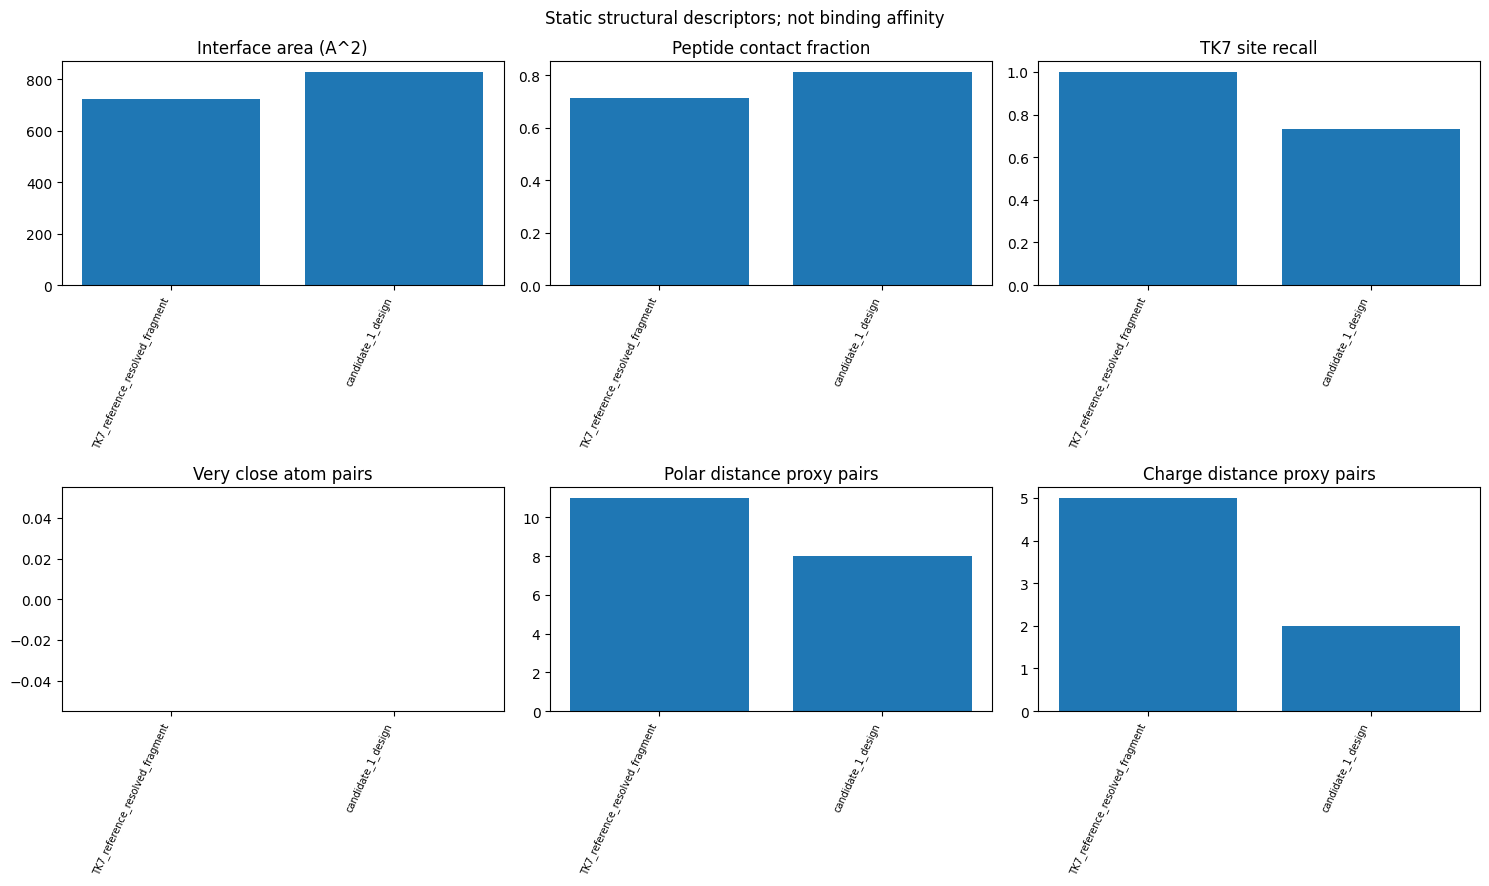

In [ ]:
#@title 6. 지표별 비교 그림 (합산 점수 아님)
import matplotlib.pyplot as plt
valid=table[table.error==''].copy()
metrics=[('interface_area_half_total_loss_A2','Interface area (A^2)'),
 ('peptide_contact_fraction_5A','Peptide contact fraction'),
 ('reference_site_recall_5A','TK7 site recall'),
 ('interchain_pairs_below_1p8A','Very close atom pairs'),
 ('donor_acceptor_distance_pairs_3p5A','Polar distance proxy pairs'),
 ('charged_sidechain_residue_pairs_4A','Charge distance proxy pairs')]
fig,axes=plt.subplots(2,3,figsize=(15,9))
for ax,(key,title) in zip(axes.flat,metrics):
    ax.bar(range(len(valid)),valid[key].astype(float))
    ax.set_xticks(range(len(valid)),valid['name'],rotation=65,ha='right',fontsize=7)
    ax.set_title(title)
fig.suptitle('Static structural descriptors; not binding affinity')
fig.tight_layout();fig.savefig(RESULTS/'comparison.png',dpi=160);plt.show()

## 지표를 읽는 방법
| 지표 | 의미와 한계 |
|---|---|
| Interface area | 결합 자세에서 가려지는 표면적. 전체 SASA 감소의 절반을 사용. 커도 결합력이 높다는 보장은 없음 |
| Peptide contact fraction | 좌표가 있는 펩타이드 잔기 중 TNIK과 5 Å 이내 접촉하는 비율 |
| TK7 site recall / Jaccard | TK7이 접촉하는 TNIK 부위를 얼마나 공유하는가. 같은 부위인지 보는 지표 |
| Very close atom pairs | 1.8 Å 미만 원자쌍. 충돌 또는 별도 결합 화학구조를 수동 점검 |
| Polar distance proxy | 공여체/수용체 후보 사이의 거리 조건. 수소·각도·양성자화 미검증이므로 수소결합 확정 수가 아님 |
| Charge distance proxy | 양/음전하 측쇄 후보 사이 거리. 실제 염다리 에너지나 친화도가 아님 |
| Sequence entropy / 반복 비율 | 서열 다양성의 기술 통계. TK7에서는 좌표가 있는 표준 잔기 부분만의 정보 |
| Target CA RMSD | 두 계산에서 표적 모양이 얼마나 다른가. 펩타이드 결합력 점수가 아님 |

두 분자의 크기·화학구조와 구조 출처가 달라 모든 항목을 일률적으로 합산할 수 없습니다.
실제 친화도 비교에는 완전한 TK7 화학구조, 두 고리와 비표준 성분의 힘장 파라미터,
동일한 TNIK 상태, 반복 MD와 검증된 자유에너지 프로토콜 또는 직접 결합 실험이 필요합니다.
MM/GBSA도 엔트로피·용매·샘플링 등의 한계가 있어 결과를 KD로 임의 변환하지 않습니다.

## 방법 자료
- SASA 방법 배경: https://freesasa.github.io/ (이 노트북은 같은 계열의 Shrake-Rupley 알고리즘을 자체 구현하며 FreeSASA 결과와 동일하지 않을 수 있음)
- PRODIGY 지원 범위(표준 아미노산): https://wenmr.science.uu.nl/prodigy/manual
- TK7 원논문: https://doi.org/10.1002/anie.2417165
- 기준 구조: https://www.rcsb.org/structure/9XW0

In [ ]:
#@title 7. 비교 결과 다운로드
import shutil
archive=shutil.make_archive(str(WORK/'TK7_candidate_comparison'),'zip',RESULTS)
files.download(archive)
print('결과 ZIP:',archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

결과 ZIP: /content/TK7_compare_20261103_120544_782559/TK7_candidate_comparison.zip
